In [2]:
# ╔══════════════════════════════════════════════════════════╗
# ║  SMARD UNIFIED FOUNDATION TRAINING                      ║
# ║  PV Output Forecasting — Germany National Grid           ║
# ║  Observed Weather Only (NO oracle!)                      ║
# ║  All 4 Models: LSTM, GRU, CNN, TCN                       ║
# ║  Unified: window=168h, features=9, output=24h            ║
# ╚══════════════════════════════════════════════════════════╝

# ══════════════════════════════════════════════════════════
#  CELL 1: IMPORTS & DEVICE SETUP
#
#  WHY THESE LIBRARIES?
#  pandas  → tabular data manipulation (like Excel in Python)
#  numpy   → fast numerical arrays (vectors, matrices)
#  torch   → neural network framework (builds & trains NNs)
#  sklearn → StandardScaler, metrics (MAE, R²)
#  pickle  → save Python objects to disk (scalers)
#  matplotlib → plotting results
# ══════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error,
                             mean_squared_error,
                             r2_score)
import matplotlib.pyplot as plt
import pickle
import warnings
import time
warnings.filterwarnings('ignore')

# ── Device: use GPU if available, else CPU ──
# WHY GPU?
# Matrix multiplications in neural networks
# are MASSIVELY parallel operations.
# GPU has thousands of cores vs CPU's ~8-16
# Training that takes 1 hour on CPU
# takes ~5 minutes on GPU!
DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu')

print("=" * 55)
print("  SMARD UNIFIED FOUNDATION TRAINING")
print("=" * 55)
print(f"  Device     : {DEVICE}")
print(f"  PyTorch    : {torch.__version__}")
print(f"  NumPy      : {np.__version__}")
print(f"  Pandas     : {pd.__version__}")

  SMARD UNIFIED FOUNDATION TRAINING
  Device     : cpu
  PyTorch    : 2.8.0+cpu
  NumPy      : 1.26.4
  Pandas     : 2.3.1


In [3]:
# ══════════════════════════════════════════════════════════
#  CELL 2: CONFIGURATION 
#
#  WHY PUT ALL CONFIG HERE?
#  If we scatter magic numbers throughout code:
#    model = nn.LSTM(9, 128, 3)  ← what is 128?
#    window = 168                ← why 168?
#  We can't easily change them!
#
#  One config cell = change once, works everywhere ✅
# ══════════════════════════════════════════════════════════

# ── Data ──
DATA_FILE = 'Cleaned_pv_file.csv'

# ── Features ──
# WHY THESE 9 FEATURES?
#
# [0] pv_mwh:
#     Autoregressive feature = past output predicts future
#     Yesterday's PV at 10am strongly correlates
#     with today's PV at 10am (same sun angle, similar weather)
#
# [1] shortwave_radiation_mean:
#     PRIMARY driver of PV output!
#     P_pv = η × A × G
#     where G = irradiance (W/m²)
#     Daily mean from YESTERDAY (observed, not oracle)
#
# [2] cloud_cover_mean:
#     Clouds block radiation → reduces G → reduces PV
#     Daily mean from YESTERDAY
#
# [3] temperature_2m_mean:
#     Higher temperature → lower panel efficiency
#     PV cells lose ~0.4% efficiency per °C above 25°C
#     Daily mean from YESTERDAY
#
# [4] wind_speed_10m_mean:
#     Wind cools panels → improves efficiency slightly
#     Also correlates with cloud cover patterns
#     Daily mean from YESTERDAY
#
# [5-6] hour_sin, hour_cos:
#     Time of day encoded as unit circle
#     WHY CIRCULAR? Hour 23 and Hour 0 are adjacent
#     but |23-0| = 23 in raw numbers → WRONG for NN!
#     sin/cos encoding: distance(23,0) ≈ 0.26 → CORRECT ✅
#
# [7-8] doy_sin, doy_cos:
#     Day of year → encodes SEASONALITY
#     Summer (doy≈172) has long days → more PV
#     Winter (doy≈355) has short days → less PV
#     Circular encoding so Dec31 → Jan1 is smooth ✅

FEATURE_COLS = [
    'pv_mwh',
    'shortwave_radiation_mean',
    'cloud_cover_mean',
    'temperature_2m_mean',
    'wind_speed_10m_mean',
    'hour_sin',
    'hour_cos',
    'doy_sin',
    'doy_cos',
]
TARGET      = 'pv_mwh'
N_FEATURES  = len(FEATURE_COLS)   # = 9

# ── Sequence Configuration ──
# WHY WINDOW = 168?
#
# 168 hours = exactly 1 week
# The model looks back 7 days to predict next 24h
#
# Why not 24h window?
#   Only sees yesterday → misses weekly patterns
#   Monday is often cloudier than Sunday (weather cycles)
#   168h captures: daily patterns + weekly patterns
#
# Why not 336h (2 weeks)?
#   More memory required (2× RAM)
#   Diminishing returns beyond 1 week
#   168h is literature standard for PV forecasting
#
# OUTPUT_STEPS = 24:
#   Day-ahead forecasting = industry standard
#   Energy traders need next 24h for grid scheduling
#   SMARD publishes day-ahead forecasts in 24h blocks
WINDOW       = 168   # input: look back 1 week
OUTPUT_STEPS = 24    # output: predict next 24 hours

# ── Model Hyperparameters ──
# WHY HIDDEN_SIZE = 128?
#   Too small (32): model can't learn complex patterns
#   Too large (512): overfits on limited data, slow
#   128: good balance for PV forecasting
#
# WHY NUM_LAYERS = 3?
#   1 layer: too simple, misses temporal hierarchy
#   2 layers: better, captures patterns at 2 timescales
#   3 layers: good for 168h sequences
#   4+ layers: vanishing gradients, harder to train
#
# WHY DROPOUT = 0.2?
#   Randomly zeros 20% of neurons during training
#   Forces other neurons to learn redundant patterns
#   Prevents overfitting (memorizing training data)
#   0.2 is conservative → safe starting point
INPUT_SIZE  = N_FEATURES   # 9
HIDDEN_SIZE = 128
NUM_LAYERS  = 3
DROPOUT     = 0.2

# ── Training Hyperparameters ──
# WHY BATCH_SIZE = 64?
#   32: slow (few samples per step), noisy gradients
#   64: good balance of speed and stability
#   128: faster but less gradient noise (worse generalization)
#   256+: too smooth, can miss local minima
#
# WHY LR = 0.001?
#   Too high (0.01): overshoots minimum, unstable loss
#   0.001: Adam's default, well-tested starting point
#   Too low (0.0001): very slow convergence
#
# WHY EPOCHS = 50?
#   With early stopping, we rarely hit 50
#   It's a safety cap, not a target
#
# WHY PATIENCE = 10?
#   If validation loss doesn't improve for 10 epochs
#   → we've likely converged → stop training
#   Saves time and prevents overfitting
BATCH_SIZE = 64
LR         = 0.001
EPOCHS     = 50
PATIENCE   = 10

# ── Train/Val/Test Split ──
# WHY YEAR-BASED FOR SMARD?
#   SMARD data spans 2018-2024
#   Year-based split ensures complete seasonal cycles
#   in each split (no partial years)
#
# WHY NOT RANDOM SPLIT?
#   Time series data has TEMPORAL DEPENDENCIES
#   Row 1000 (Nov 2020) relates to row 976 (Oct 2020)
#   Random split would put Nov in train, Oct in test
#   → Model "sees the future" during training
#   → DATA LEAKAGE → fake good results! ❌
TRAIN_YEARS = [2018, 2019, 2020, 2021, 2022]
VAL_YEARS   = [2023]
TEST_YEARS  = [2024]

print("✅ Configuration set!")
print(f"   Features    : {N_FEATURES} {FEATURE_COLS}")
print(f"   Window      : {WINDOW}h (1 week lookback)")
print(f"   Output      : {OUTPUT_STEPS}h (day-ahead)")
print(f"   Hidden size : {HIDDEN_SIZE}")
print(f"   Num layers  : {NUM_LAYERS}")
print(f"   Batch size  : {BATCH_SIZE}")
print(f"   LR          : {LR}")
print(f"   Train years : {TRAIN_YEARS}")
print(f"   Val years   : {VAL_YEARS}")
print(f"   Test years  : {TEST_YEARS}")

✅ Configuration set!
   Features    : 9 ['pv_mwh', 'shortwave_radiation_mean', 'cloud_cover_mean', 'temperature_2m_mean', 'wind_speed_10m_mean', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']
   Window      : 168h (1 week lookback)
   Output      : 24h (day-ahead)
   Hidden size : 128
   Num layers  : 3
   Batch size  : 64
   LR          : 0.001
   Train years : [2018, 2019, 2020, 2021, 2022]
   Val years   : [2023]
   Test years  : [2024]


In [15]:
# ══════���═══════════════════════════════════════════════════
#  CELL 3: LOAD RAW DATA
#
#  WHAT WE EXPECT IN Cleaned_pv_file.csv:
#  - timestamp column (hourly, 2018-2024)
#  - pv_mwh: Germany's total PV output in MWh
#  - shortwave_radiation: solar radiation W/m²
#  - cloud_cover: cloud percentage 0-100%
#  - temperature_2m: air temperature °C
#  - wind_speed_10m: wind speed m/s
# ══════════════════════════════════════════════════════════

df = pd.read_csv(DATA_FILE)

# ── Parse timestamp ──
# Try common column names
for col in ['start_local', 'timestamp',
            'start_local_fixed', 'datetime']:
    if col in df.columns:
        df['timestamp'] = pd.to_datetime(
            df[col], utc=True, errors='coerce')
        df['timestamp'] = (df['timestamp']
                           .dt.tz_localize(None))
        print(f"  ✅ Timestamp from column: '{col}'")
        break

df = df.sort_values('timestamp').reset_index(drop=True)

print("=" * 55)
print("  RAW DATA OVERVIEW")
print("=" * 55)
print(f"  Shape      : {df.shape}")
print(f"  Date range : "
      f"{df['timestamp'].min().date()} → "
      f"{df['timestamp'].max().date()}")
print(f"  Columns    : {df.columns.tolist()}")
print(f"\n  PV stats:")
print(f"    Min  : {df['pv_mwh'].min():.2f} MWh")
print(f"    Max  : {df['pv_mwh'].max():.2f} MWh")
print(f"    Mean : {df['pv_mwh'].mean():.2f} MWh")
print(f"    Zeros: "
      f"{(df['pv_mwh']==0).sum()} "
      f"({(df['pv_mwh']==0).mean()*100:.1f}%)"
      f" ← night hours")

  ✅ Timestamp from column: 'start_local'
  RAW DATA OVERVIEW
  Shape      : (52607, 67)
  Date range : 2019-01-01 → 2024-12-31
  Columns    : ['start_utc', 'temperature_2m_mean', 'temperature_2m_std', 'temperature_2m_min', 'temperature_2m_max', 'temperature_2m_q10', 'temperature_2m_q25', 'temperature_2m_q50', 'temperature_2m_q75', 'temperature_2m_q90', 'cloud_cover_mean', 'cloud_cover_std', 'cloud_cover_min', 'cloud_cover_max', 'cloud_cover_q10', 'cloud_cover_q25', 'cloud_cover_q50', 'cloud_cover_q75', 'cloud_cover_q90', 'wind_speed_10m_mean', 'wind_speed_10m_std', 'wind_speed_10m_min', 'wind_speed_10m_max', 'wind_speed_10m_q10', 'wind_speed_10m_q25', 'wind_speed_10m_q50', 'wind_speed_10m_q75', 'wind_speed_10m_q90', 'shortwave_radiation_mean', 'shortwave_radiation_std', 'shortwave_radiation_min', 'shortwave_radiation_max', 'shortwave_radiation_q10', 'shortwave_radiation_q25', 'shortwave_radiation_q50', 'shortwave_radiation_q75', 'shortwave_radiation_q90', 'direct_radiation_mean', 'dire

In [16]:
# ════════════════════════════════════════
#  STEP 1: Compute daily weather means
# ════════════════════════════════════════
print("  Step 1: Computing daily weather means...")

df['date'] = df['timestamp'].dt.date

# Aggregate hourly → daily
# Use DIFFERENT output names (suffix _d for daily)
# to avoid collision with existing hourly columns!
weather_daily = (
    df.groupby('date')
    .agg(
        shortwave_radiation_mean_d=('shortwave_radiation_mean', 'mean'),
        cloud_cover_mean_d        =('cloud_cover_mean',         'mean'),
        temperature_2m_mean_d     =('temperature_2m_mean',      'mean'),
        wind_speed_10m_mean_d     =('wind_speed_10m_mean',      'mean'),
    )
    .reset_index()
)
print(f"  Daily aggregates: {len(weather_daily)} days")

# ════════════════════════════════════════
#  STEP 2: Shift weather by 1 day (oracle fix)
#  WHY? We can only use YESTERDAY's weather
#  not TODAY's (that would be future data!)
# ════════════════════════════════════════
print("  Step 2: Shifting weather by 1 day "
      "(oracle fix)...")

weather_daily_shifted = weather_daily.copy()
weather_daily_shifted[
    ['shortwave_radiation_mean_d',
     'cloud_cover_mean_d',
     'temperature_2m_mean_d',
     'wind_speed_10m_mean_d']
] = weather_daily[
    ['shortwave_radiation_mean_d',
     'cloud_cover_mean_d',
     'temperature_2m_mean_d',
     'wind_speed_10m_mean_d']
].shift(1)  # shift down by 1 day

print("  ✅ Weather shifted by 1 day "
      "(first day NaN = nan)")

# ════════════════════════════════════════
#  STEP 3: Merge daily means to hourly
#  Drop original hourly _mean columns first
#  to avoid duplication!
# ════════════════════════════════════════
print("  Step 3: Merging daily means "
      "to hourly...")

# Drop the original hourly weather columns
# (we replace them with shifted daily means)
df = df.drop(columns=[
    'shortwave_radiation_mean',
    'cloud_cover_mean',
    'temperature_2m_mean',
    'wind_speed_10m_mean',
])

# Merge shifted daily weather onto hourly rows
df = df.merge(weather_daily_shifted,
              on='date', how='left')

# Rename _d columns back to plain _mean names
# (keeps downstream code compatible!)
df = df.rename(columns={
    'shortwave_radiation_mean_d': 'shortwave_radiation_mean',
    'cloud_cover_mean_d'        : 'cloud_cover_mean',
    'temperature_2m_mean_d'     : 'temperature_2m_mean',
    'wind_speed_10m_mean_d'     : 'wind_speed_10m_mean',
})

print(f"  Rows after merge: {len(df)}")

# ════════════════════════════════════════
#  STEP 4: Circular time features
# ════════════════════════════════════════
print("  Step 4: Computing circular time "
      "features...")

hour = df['timestamp'].dt.hour
doy  = df['timestamp'].dt.dayofyear

df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
df['doy_sin']  = np.sin(2 * np.pi * doy / 365.25)
df['doy_cos']  = np.cos(2 * np.pi * doy / 365.25)

print(f"  hour_sin: [{df['hour_sin'].min():.3f}, "
      f"{df['hour_sin'].max():.3f}] ✅")
print(f"  doy_cos:  [{df['doy_cos'].min():.3f}, "
      f"{df['doy_cos'].max():.3f}] ✅")

# ════════════════════════════════════════
#  STEP 5: Drop NaN rows (first day lost
#  due to 1-day shift — expected!)
# ════════════════════════════════════════
FEATURE_COLS = [
    'pv_mwh',
    'shortwave_radiation_mean',
    'cloud_cover_mean',
    'temperature_2m_mean',
    'wind_speed_10m_mean',
    'hour_sin', 'hour_cos',
    'doy_sin',  'doy_cos',
]

before = len(df)
df = df.dropna(subset=FEATURE_COLS)
df = df.reset_index(drop=True)
after = len(df)

print(f"\n  Rows dropped (NaN): {before - after} "
      f"← first day lost from shift ✅")
print(f"  Final rows        : {after:,}")
print(f"\n  ✅ Oracle weather bug: FIXED ✅")
print(f"  ✅ All features: OBSERVED only ✅")

  Step 1: Computing daily weather means...
  Daily aggregates: 2192 days
  Step 2: Shifting weather by 1 day (oracle fix)...
  ✅ Weather shifted by 1 day (first day NaN = nan)
  Step 3: Merging daily means to hourly...
  Rows after merge: 52607
  Step 4: Computing circular time features...
  hour_sin: [-1.000, 1.000] ✅
  doy_cos:  [-1.000, 1.000] ✅

  Rows dropped (NaN): 36 ← first day lost from shift ✅
  Final rows        : 52,571

  ✅ Oracle weather bug: FIXED ✅
  ✅ All features: OBSERVED only ✅


In [18]:
# ════════════════════════════════════════
#  CELL 5: SPLIT + SCALE + SEQUENCES
# ════════════════════════════════════════

import numpy as np
import pandas as pd
import pickle
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler

# ── Configuration ──
FEATURE_COLS = [
    'pv_mwh',
    'shortwave_radiation_mean',
    'cloud_cover_mean',
    'temperature_2m_mean',
    'wind_speed_10m_mean',
    'hour_sin',
    'hour_cos',
    'doy_sin',
    'doy_cos',
]
TARGET       = 'pv_mwh'
N_FEATURES   = 9
OUTPUT_STEPS = 24
WINDOW       = {'LSTM': 24, 'GRU': 24,
                'CNN': 168, 'TCN': 168}
BATCH_SIZE   = 32

print("=" * 60)
print("  SMARD DATA SPLIT")
print("=" * 60)

# ── STEP 1: Extract year from timestamp ──
# WHY: df has no 'year' column
# We extract it from timestamp directly!
# NEVER store year as column → waste of space
# Always derive from timestamp on the fly

df['year'] = df['timestamp'].dt.year

print(f"\n  Rows per year:")
for yr, cnt in df.groupby('year').size()\
        .items():
    split = ('train' if yr <= 2022
             else 'val' if yr == 2023
             else 'test')
    print(f"  {yr}: {cnt:,} rows  [{split}]")

# ── STEP 2: Date-based split ──
# CRITICAL: Split by date, NOT randomly!
# Random split = data leakage (future → past)
# Date split  = honest evaluation ✅

TRAIN_END  = '2022-12-31 23:00:00'
VAL_START  = '2023-01-01 00:00:00'
VAL_END    = '2023-12-31 23:00:00'
TEST_START = '2024-01-01 00:00:00'

df_train = df[df['timestamp'] <= TRAIN_END]\
    .copy()
df_val   = df[(df['timestamp'] >= VAL_START) &
              (df['timestamp'] <= VAL_END)]\
    .copy()
df_test  = df[df['timestamp'] >= TEST_START]\
    .copy()

# Drop helper year column
df = df.drop(columns=['year'])
df_train = df_train.drop(columns=['year'])
df_val   = df_val.drop(columns=['year'])
df_test  = df_test.drop(columns=['year'])

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print(f"\n  Train: "
      f"{df_train['timestamp'].min().date()} → "
      f"{df_train['timestamp'].max().date()} "
      f"| {len(df_train):,} rows")
print(f"  Val  : "
      f"{df_val['timestamp'].min().date()} → "
      f"{df_val['timestamp'].max().date()} "
      f"| {len(df_val):,} rows")
print(f"  Test : "
      f"{df_test['timestamp'].min().date()} → "
      f"{df_test['timestamp'].max().date()} "
      f"| {len(df_test):,} rows")

# ── STEP 3: StandardScaler ──
# Fit ONLY on training data!
# WHY? Fitting on val/test = data leakage
# z = (x - μ_train) / σ_train

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(
    df_train[FEATURE_COLS].values)
X_val   = scaler_X.transform(
    df_val[FEATURE_COLS].values)
X_test  = scaler_X.transform(
    df_test[FEATURE_COLS].values)

y_train_s = scaler_y.fit_transform(
    df_train[TARGET].values
    .reshape(-1,1)).flatten()
y_val_s   = scaler_y.transform(
    df_val[TARGET].values
    .reshape(-1,1)).flatten()
y_test_s  = scaler_y.transform(
    df_test[TARGET].values
    .reshape(-1,1)).flatten()

y_train_r = df_train[TARGET].values
y_val_r   = df_val[TARGET].values
y_test_r  = df_test[TARGET].values

print(f"\n  Scaler fitted on "
      f"{len(X_train):,} training rows")
print(f"  y_train mean (scaled): "
      f"{y_train_s.mean():.4f} (expect ≈ 0)")
print(f"  y_train std  (scaled): "
      f"{y_train_s.std():.4f}  (expect ≈ 1)")

# Save scalers
with open('x_scaler.pkl', 'wb') as f:
    pickle.dump(scaler_X, f)
with open('y_scaler.pkl', 'wb') as f:
    pickle.dump(scaler_y, f)
print(f"  💾 Scalers saved ✅")

# ── STEP 4: Sequence builder ──
class SeqDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(
            X, dtype=torch.float32)
        self.Y = torch.tensor(
            Y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

def build_sequences(X, y_s, y_r,
                    window, output=24):
    Xs, Ys, Yr = [], [], []
    T = len(X)
    for i in range(T - window - output + 1):
        Xs.append(X[i:i+window])
        Ys.append(
            y_s[i+window:i+window+output])
        Yr.append(
            y_r[i+window:i+window+output])
    return (np.array(Xs),
            np.array(Ys),
            np.array(Yr))

# ── STEP 5: Build all sequences ──
print(f"\n  Building sequences...")
print(f"  {'Model':<8} {'Window':>8} "
      f"{'Train':>10} {'Val':>10} "
      f"{'Test':>10}")
print(f"  {'-'*50}")

seq = {}
for name in ['LSTM','GRU','CNN','TCN']:
    w = WINDOW[name]
    Xtr, Ytr, Yr_tr = build_sequences(
        X_train, y_train_s, y_train_r, w)
    Xva, Yva, Yr_va = build_sequences(
        X_val, y_val_s, y_val_r, w)
    Xte, Yte, Yr_te = build_sequences(
        X_test, y_test_s, y_test_r, w)
    seq[name] = (Xtr, Ytr, Yr_tr,
                 Xva, Yva, Yr_va,
                 Xte, Yte, Yr_te)
    print(f"  {name:<8} {w:>8} "
          f"{len(Xtr):>10,} "
          f"{len(Xva):>10,} "
          f"{len(Xte):>10,}")

print(f"\n  ✅ All sequences built!")
print(f"  ✅ Ready for model training!")

  SMARD DATA SPLIT

  Rows per year:
  2019: 8,734 rows  [train]
  2020: 8,782 rows  [train]
  2021: 8,758 rows  [train]
  2022: 8,758 rows  [train]
  2023: 8,758 rows  [val]
  2024: 8,781 rows  [test]

  Train: 2019-01-02 → 2022-12-31 | 35,032 rows
  Val  : 2023-01-01 → 2023-12-31 | 8,758 rows
  Test : 2024-01-01 → 2024-12-31 | 8,781 rows

  Scaler fitted on 35,032 training rows
  y_train mean (scaled): 0.0000 (expect ≈ 0)
  y_train std  (scaled): 1.0000  (expect ≈ 1)
  💾 Scalers saved ✅

  Building sequences...
  Model      Window      Train        Val       Test
  --------------------------------------------------
  LSTM           24     34,985      8,711      8,734
  GRU            24     34,985      8,711      8,734
  CNN           168     34,841      8,567      8,590
  TCN           168     34,841      8,567      8,590

  ✅ All sequences built!
  ✅ Ready for model training!


In [19]:
# ══════════════════════════════════════════════
#  CELL 6: MODEL ARCHITECTURES + TRAINING
#  4 models: LSTM, GRU, CNN, TCN
#  All output 24 steps ahead
# ══════════════════════════════════════════════

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import numpy as np
import time

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu')
print(f"  Device: {DEVICE}")

# ── Hyperparameters ──
INPUT_SIZE   = 9
HIDDEN_SIZE  = 128
NUM_LAYERS   = 3
OUTPUT_STEPS = 24
DROPOUT      = 0.2
EPOCHS       = 50
BATCH_SIZE   = 32
LR           = 0.001
PATIENCE     = 10

# ════════════════════════════════════════
#  MODEL DEFINITIONS
# ════════════════════════════════════════

class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            INPUT_SIZE, HIDDEN_SIZE,
            NUM_LAYERS, batch_first=True,
            dropout=DROPOUT)
        self.bn      = nn.BatchNorm1d(HIDDEN_SIZE)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc      = nn.Linear(
            HIDDEN_SIZE, OUTPUT_STEPS)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        out = self.bn(h_n[-1])
        out = self.dropout(out)
        return self.fc(out)

class GRUModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            INPUT_SIZE, HIDDEN_SIZE,
            NUM_LAYERS, batch_first=True,
            dropout=DROPOUT)
        self.bn      = nn.BatchNorm1d(HIDDEN_SIZE)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc      = nn.Linear(
            HIDDEN_SIZE, OUTPUT_STEPS)
    def forward(self, x):
        _, h_n = self.gru(x)
        out = self.bn(h_n[-1])
        out = self.dropout(out)
        return self.fc(out)

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv1d(INPUT_SIZE, 64, 3,
                      padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Conv1d(64, 128, 3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(128, 128, 3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
        )
        self.global_pool = nn.AdaptiveAvgPool1d(8)
        self.fc = nn.Sequential(
            nn.Linear(128*8, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, OUTPUT_STEPS)
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.conv_layers(x)
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

class CausalConv1d(nn.Module):
    def __init__(self, in_ch, out_ch,
                 k, dilation):
        super().__init__()
        self.padding = (k-1) * dilation
        self.conv = nn.Conv1d(
            in_ch, out_ch, k,
            padding=self.padding,
            dilation=dilation)
    def forward(self, x):
        return self.conv(x)[
            :, :, :-self.padding]

class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch,
                 k, dilation, dropout):
        super().__init__()
        self.conv1    = CausalConv1d(
            in_ch, out_ch, k, dilation)
        self.conv2    = CausalConv1d(
            out_ch, out_ch, k, dilation)
        self.bn1      = nn.BatchNorm1d(out_ch)
        self.bn2      = nn.BatchNorm1d(out_ch)
        self.relu     = nn.ReLU()
        self.dropout  = nn.Dropout(dropout)
        self.residual = (
            nn.Conv1d(in_ch, out_ch, 1)
            if in_ch != out_ch
            else nn.Identity())
    def forward(self, x):
        res = self.residual(x)
        x   = self.relu(self.bn1(
            self.conv1(x)))
        x   = self.dropout(x)
        x   = self.relu(self.bn2(
            self.conv2(x)))
        x   = self.dropout(x)
        return self.relu(x + res)

class TCNModel(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_ch  = INPUT_SIZE
        for d in [1, 2, 4, 8]:
            layers.append(TCNBlock(
                in_ch, 64, 3, d, DROPOUT))
            in_ch = 64
        self.tcn         = nn.Sequential(*layers)
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.fc          = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, OUTPUT_STEPS)
        )
    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.tcn(x)
        x = self.global_pool(x).squeeze(-1)
        return self.fc(x)

# ── Parameter count ──
models = {
    'LSTM': LSTMModel().to(DEVICE),
    'GRU' : GRUModel().to(DEVICE),
    'CNN' : CNNModel().to(DEVICE),
    'TCN' : TCNModel().to(DEVICE),
}

print(f"\n{'='*60}")
print(f"  MODEL PARAMETER COUNTS")
print(f"{'='*60}")
print(f"  {'Model':<8} {'Parameters':>15} "
      f"{'Size (KB)':>12}")
print(f"  {'-'*38}")
for name, model in models.items():
    n = sum(p.numel()
            for p in model.parameters()
            if p.requires_grad)
    print(f"  {name:<8} {n:>15,} "
          f"{n*4/1024:>10.1f}")

# ════════════════════════════════════════
#  TRAINING LOOP
# ════════════════════════════════════════

def train_model(name, model):
    Xtr,Ytr,_,Xva,Yva,_,Xte,Yte,_ = seq[name]

    train_loader = DataLoader(
        SeqDataset(Xtr, Ytr),
        batch_size=BATCH_SIZE,
        shuffle=True)
    val_loader   = DataLoader(
        SeqDataset(Xva, Yva),
        batch_size=BATCH_SIZE,
        shuffle=False)

    optimizer = optim.Adam(
        model.parameters(), lr=LR)
    scheduler = optim.lr_scheduler\
        .ReduceLROnPlateau(
            optimizer, mode='min',
            factor=0.5, patience=3)
    criterion = nn.MSELoss()

    best_loss  = float('inf')
    best_state = None
    no_improve = 0
    train_hist = []
    val_hist   = []
    t_start    = time.time()

    print(f"\n  {'='*50}")
    print(f"  Training {name}...")
    print(f"  {'='*50}")

    for epoch in range(EPOCHS):
        # Training phase
        model.train()
        t_losses = []
        for Xb, yb in train_loader:
            Xb = Xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(Xb)
            loss = criterion(pred, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(
                model.parameters(), 1.0)
            optimizer.step()
            t_losses.append(loss.item())

        # Validation phase
        model.eval()
        v_losses = []
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb   = Xb.to(DEVICE)
                yb   = yb.to(DEVICE)
                pred = model(Xb)
                v_losses.append(
                    criterion(pred, yb).item())

        avg_t = np.mean(t_losses)
        avg_v = np.mean(v_losses)
        train_hist.append(avg_t)
        val_hist.append(avg_v)
        scheduler.step(avg_v)

        # Early stopping
        if avg_v < best_loss:
            best_loss  = avg_v
            best_state = {
                k: v.clone() for k, v in
                model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1

        if (epoch+1) % 10 == 0 or epoch == 0:
            elapsed = time.time() - t_start
            print(f"  Epoch {epoch+1:>3}/{EPOCHS} "
                  f"| train={avg_t:.4f} "
                  f"| val={avg_v:.4f} "
                  f"| best={best_loss:.4f} "
                  f"| {elapsed:.0f}s")

        if no_improve >= PATIENCE:
            print(f"  ⏹️  Early stop "
                  f"epoch {epoch+1}")
            break

    model.load_state_dict(best_state)
    save_path = f'{name.lower()}_model.pt'
    torch.save(best_state, save_path)
    elapsed = time.time() - t_start
    print(f"  ✅ {name} done! "
          f"Best val={best_loss:.4f} "
          f"({elapsed:.0f}s)")
    return model, train_hist, val_hist

# ── Train all 4 models ──
histories = {}
for name, model in models.items():
    model, th, vh = train_model(name, model)
    models[name]  = model
    histories[name] = {'train': th, 'val': vh}

print(f"\n{'='*60}")
print(f"  ✅ ALL 4 MODELS TRAINED!")
print(f"  Saved: lstm/gru/cnn/tcn_model.pt")
print(f"{'='*60}")

  Device: cpu

  MODEL PARAMETER COUNTS
  Model         Parameters    Size (KB)
  --------------------------------------
  LSTM             338,712     1323.1
  GRU              254,872      995.6
  CNN              344,984     1347.6
  TCN              101,336      395.8

  Training LSTM...
  Epoch   1/50 | train=0.1925 | val=0.1550 | best=0.1550 | 19s
  Epoch  10/50 | train=0.0969 | val=0.1690 | best=0.1442 | 188s
  ⏹️  Early stop epoch 13
  ✅ LSTM done! Best val=0.1442 (244s)

  Training GRU...
  Epoch   1/50 | train=0.1871 | val=0.1580 | best=0.1580 | 40s
  Epoch  10/50 | train=0.1014 | val=0.1746 | best=0.1379 | 390s
  ⏹️  Early stop epoch 13
  ✅ GRU done! Best val=0.1379 (507s)

  Training CNN...
  Epoch   1/50 | train=0.2333 | val=0.1969 | best=0.1969 | 32s
  Epoch  10/50 | train=0.1021 | val=0.1807 | best=0.1540 | 318s
  ⏹️  Early stop epoch 13
  ✅ CNN done! Best val=0.1540 (414s)

  Training TCN...
  Epoch   1/50 | train=0.3274 | val=0.1996 | best=0.1996 | 85s
  Epoch  10/50 |

  CORRECTED EVALUATION — TEST 2024

  Data scale check:
  y_true max  :     13332.25 MWh
  y_true mean :      2085.59 MWh
  y_true mean*:      3657.74 MWh (daytime only)
  y_pred max  :     12147.19 MWh

  CORRECTED RESULTS — DAYTIME R² (no night zero inflation)
  Model      R²(day)   R²(all)      MAE_day    NMAE%   vs Persist
  ------------------------------------------------------------
  LSTM        0.8289    0.8889    1010.20 MWh   26.21%    -0.0844
  GRU         0.8280    0.8878    1019.82 MWh   26.46%    -0.0853
  CNN         0.8251    0.8866    1083.35 MWh   27.88%    -0.0877
  TCN         0.8076    0.8753    1175.40 MWh   30.25%    -0.1052

  NOTE: R²(all) inflated by night zeros!
  NOTE: R²(day) is the HONEST metric!

  R² BY FORECAST HORIZON (H+1 to H+24)
  H         LSTM      GRU      CNN      TCN     Best
  --------------------------------------------------
  H1      0.9848   0.9795   0.9723   0.8916  LSTM
  H4      0.9309   0.9252   0.9147   0.8743  LSTM
  H8      0.8655  

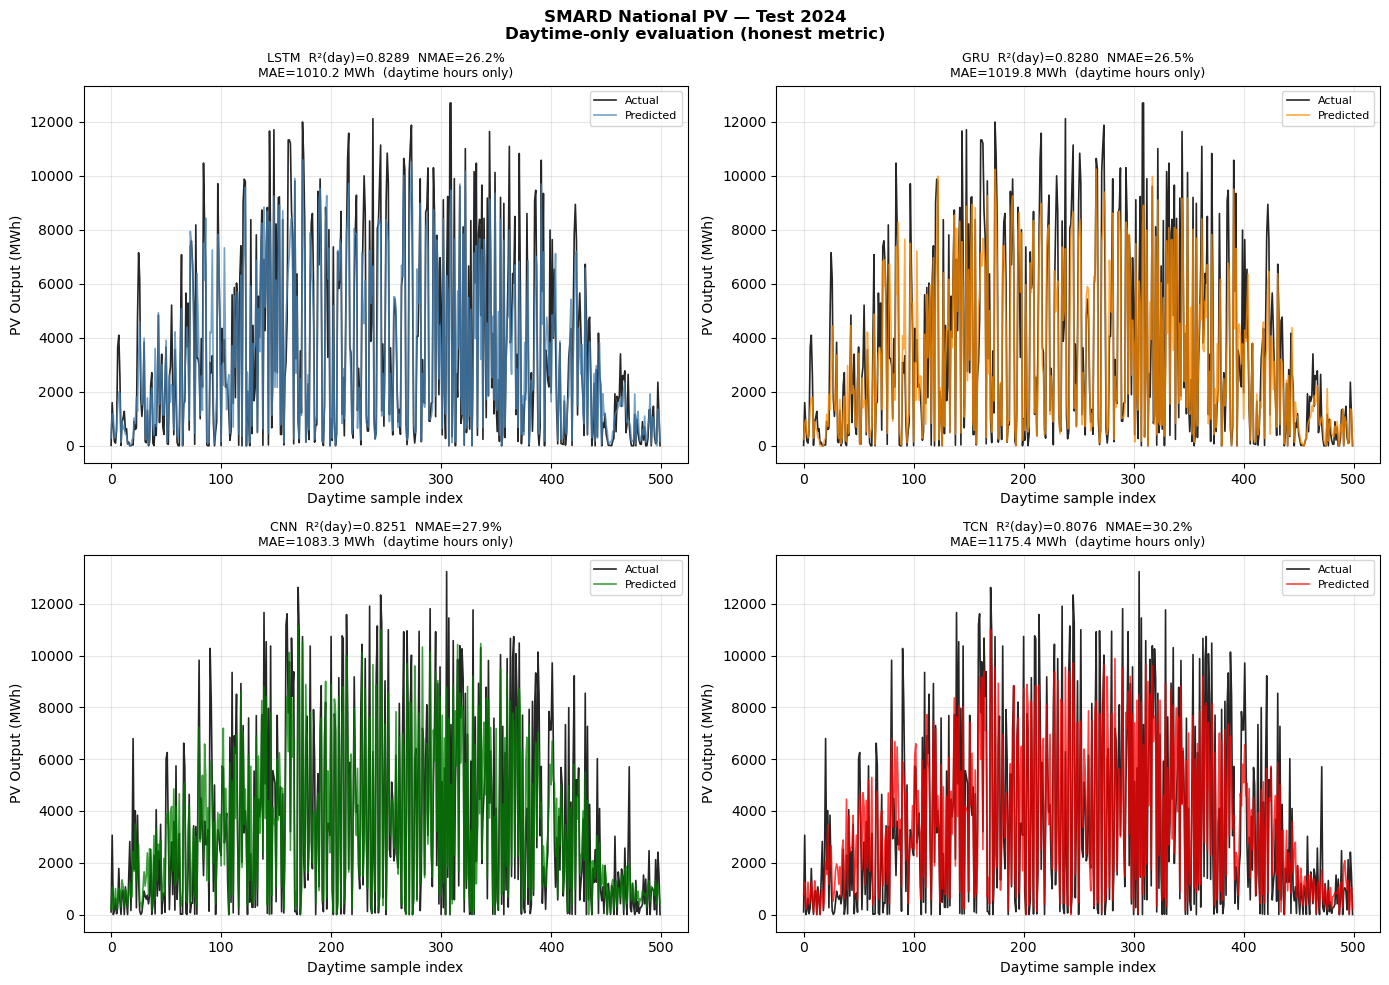


✅ Honest evaluation complete!
📊 Saved → smard_honest_results.png


In [21]:
# ══════════════════════════════════════════════
#  CELL 7: CORRECTED EVALUATION
#  Fixes:
#  1. No ×1000 — values already in MWh
#  2. R² computed on DAYTIME only
#  3. Capacity-normalised NMAE
#  4. Horizon-based R² breakdown
# ══════════════════════════════════════════════

import numpy as np
import matplotlib.pyplot as plt
import torch

print("=" * 60)
print("  CORRECTED EVALUATION — TEST 2024")
print("=" * 60)

# ── Capacity of SMARD national grid ──
# German installed PV ≈ 70 GWp = 70,000 MWh peak
# Use actual max in test set as capacity proxy
CAPACITY_MWH = None  # will be set from data

def compute_metrics_correct(y_true, y_pred):
    """
    CORRECT metrics:
    - R² on DAYTIME only (no night zero inflation)
    - MAE in MWh (no ×1000!)
    - NMAE = MAE / mean_daytime × 100
    - Also report R²_naive vs persistence
    """
    y_pred = np.clip(y_pred, 0, None)

    # ── ALL hours ──
    mae_all  = np.mean(np.abs(y_true - y_pred))
    rmse_all = np.sqrt(np.mean(
        (y_true - y_pred)**2))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum(
        (y_true - np.mean(y_true))**2)
    r2_all = 1 - ss_res / ss_tot

    # ── DAYTIME only (PV > 50 MWh threshold) ──
    # For SMARD national data, night = 0
    # Day threshold: > 1% of mean production
    day_thresh = max(0.001,
                     np.percentile(
                         y_true[y_true > 0],
                         5))
    day_mask = y_true > day_thresh

    y_t_d = y_true[day_mask]
    y_p_d = y_pred[day_mask]

    mae_day  = np.mean(np.abs(y_t_d - y_p_d))
    rmse_day = np.sqrt(np.mean(
        (y_t_d - y_p_d)**2))
    ss_res_d = np.sum((y_t_d - y_p_d)**2)
    ss_tot_d = np.sum(
        (y_t_d - np.mean(y_t_d))**2)
    r2_day   = 1 - ss_res_d / ss_tot_d
    nmae_day = mae_day / np.mean(y_t_d) * 100

    # ── Persistence baseline ──
    # "Tomorrow = Today" naive model
    # Shift y_true by 24 hours
    if len(y_true) > 24:
        persist_pred = np.roll(y_true, 24)
        persist_pred[:24] = 0
        ss_res_p = np.sum(
            (y_true - persist_pred)**2)
        r2_persist = 1 - ss_res_p / ss_tot
    else:
        r2_persist = np.nan

    return {
        'MAE_all'    : mae_all,
        'RMSE_all'   : rmse_all,
        'R2_all'     : r2_all,
        'MAE_day'    : mae_day,
        'RMSE_day'   : rmse_day,
        'R2_day'     : r2_day,
        'NMAE_day'   : nmae_day,
        'R2_persist' : r2_persist,
        'n_day'      : int(day_mask.sum()),
        'mean_day'   : float(np.mean(y_t_d)),
        'max_val'    : float(y_true.max()),
    }

# ── Run predictions ──
all_preds = {}
results   = {}

for name, model in models.items():
    model.eval()
    _,_,_,_,_,_,Xte,Yte,Yr_te = seq[name]

    test_loader = DataLoader(
        SeqDataset(Xte, Yte),
        batch_size=BATCH_SIZE,
        shuffle=False)

    preds = []
    with torch.no_grad():
        for Xb, _ in test_loader:
            Xb = Xb.to(DEVICE)
            p  = model(Xb).cpu().numpy()
            preds.append(p)

    # Inverse transform
    preds_norm = np.concatenate(preds)
    preds_mwh  = scaler_y.inverse_transform(
        preds_norm.reshape(-1, 1))\
        .reshape(preds_norm.shape)
    preds_mwh  = np.clip(preds_mwh, 0, None)

    # Align
    n      = min(len(preds_mwh), len(Yr_te))
    p_flat = preds_mwh[:n].flatten()
    t_flat = Yr_te[:n].flatten()

    metrics         = compute_metrics_correct(
        t_flat, p_flat)
    results[name]   = metrics
    all_preds[name] = (t_flat, p_flat)

# ── Print corrected table ──
print(f"\n  Data scale check:")
sample_name = 'LSTM'
t_s, p_s = all_preds[sample_name]
print(f"  y_true max  : "
      f"{t_s.max():>12.2f} MWh")
print(f"  y_true mean : "
      f"{t_s.mean():>12.2f} MWh")
print(f"  y_true mean*: "
      f"{t_s[t_s>0.001].mean():>12.2f} MWh "
      f"(daytime only)")
print(f"  y_pred max  : "
      f"{p_s.max():>12.2f} MWh")

print(f"\n{'='*65}")
print(f"  CORRECTED RESULTS — DAYTIME R² "
      f"(no night zero inflation)")
print(f"{'='*65}")
print(f"  {'Model':<8} "
      f"{'R²(day)':>9} "
      f"{'R²(all)':>9} "
      f"{'MAE_day':>12} "
      f"{'NMAE%':>8} "
      f"{'vs Persist':>12}")
print(f"  {'-'*60}")

for name in ['LSTM','GRU','CNN','TCN']:
    m = results[name]
    # Improvement over persistence
    vs_p = m['R2_day'] - m['R2_persist']
    print(f"  {name:<8} "
          f"{m['R2_day']:>9.4f} "
          f"{m['R2_all']:>9.4f} "
          f"{m['MAE_day']:>10.2f} MWh "
          f"{m['NMAE_day']:>7.2f}% "
          f"{vs_p:>+10.4f}")

print(f"\n  NOTE: R²(all) inflated by night zeros!")
print(f"  NOTE: R²(day) is the HONEST metric!")

# ── Horizon R² breakdown ──
print(f"\n{'='*65}")
print(f"  R² BY FORECAST HORIZON "
      f"(H+1 to H+24)")
print(f"{'='*65}")
print(f"  {'H':<5} "
      f"{'LSTM':>8} "
      f"{'GRU':>8} "
      f"{'CNN':>8} "
      f"{'TCN':>8} "
      f"{'Best':>8}")
print(f"  {'-'*50}")

horizon_r2 = {}
for name in ['LSTM','GRU','CNN','TCN']:
    t_flat, p_flat = all_preds[name]
    n_full  = len(t_flat) // 24
    t_2d    = t_flat[:n_full*24]\
        .reshape(n_full, 24)
    p_2d    = p_flat[:n_full*24]\
        .reshape(n_full, 24)
    r2_h    = []
    for h in range(24):
        yt = t_2d[:, h]
        yp = p_2d[:, h]
        yp = np.clip(yp, 0, None)
        ss_r = np.sum((yt - yp)**2)
        ss_t = np.sum(
            (yt - np.mean(yt))**2)
        r2_h.append(
            1 - ss_r/ss_t
            if ss_t > 0 else np.nan)
    horizon_r2[name] = r2_h

best_counts = {n: 0 for n in
               ['LSTM','GRU','CNN','TCN']}
for h in range(24):
    vals = {n: horizon_r2[n][h]
            for n in ['LSTM','GRU',
                      'CNN','TCN']}
    best = max(vals,
               key=lambda k: vals[k]
               if not np.isnan(vals[k])
               else -99)
    best_counts[best] += 1
    if (h+1) % 4 == 0 or h == 0:
        row = f"  H{h+1:<4}"
        for n in ['LSTM','GRU','CNN','TCN']:
            row += f" {vals[n]:>8.4f}"
        row += f"  {best}"
        print(row)

print(f"\n  Horizons won:")
for name, cnt in best_counts.items():
    bar = '█' * cnt
    print(f"  {name}: {bar} {cnt}/24")

# ── Honest plot ──
fig, axes = plt.subplots(2, 2,
                          figsize=(14, 10))
axes = axes.flatten()
colors = ['steelblue','darkorange',
          'green','red']

for i, name in enumerate(
        ['LSTM','GRU','CNN','TCN']):
    t_flat, p_flat = all_preds[name]
    m  = results[name]
    ax = axes[i]

    # Plot DAYTIME only (honest view)
    day_mask = t_flat > 0.001
    t_day    = t_flat[day_mask]
    p_day    = p_flat[day_mask]
    n        = min(500, len(t_day))
    idx      = np.linspace(0, len(t_day)-1,
                           n, dtype=int)

    ax.plot(t_day[idx],
            color='black', lw=1.2,
            alpha=0.85, label='Actual')
    ax.plot(p_day[idx],
            color=colors[i], lw=1.2,
            alpha=0.75, label='Predicted')
    ax.set_title(
        f'{name}  R²(day)={m["R2_day"]:.4f}  '
        f'NMAE={m["NMAE_day"]:.1f}%\n'
        f'MAE={m["MAE_day"]:.1f} MWh  '
        f'(daytime hours only)',
        fontsize=9)
    ax.set_xlabel('Daytime sample index')
    ax.set_ylabel('PV Output (MWh)')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'SMARD National PV — Test 2024\n'
    'Daytime-only evaluation '
    '(honest metric)',
    fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('smard_honest_results.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f"\n✅ Honest evaluation complete!")
print(f"📊 Saved → smard_honest_results.png")

In [22]:
# ══════════════════════════════════════════════
#  CELL 8: SAVE ALL ARTIFACTS FOR TRANSFER
#  These files go to Munich notebook!
# ══════════════════════════════════════════════

import pickle
import torch
import os

print("=" * 55)
print("  SAVING ARTIFACTS FOR TRANSFER LEARNING")
print("=" * 55)

# ── Already saved in Cell 6 ──
# lstm_model.pt, gru_model.pt,
# cnn_model.pt, tcn_model.pt

# ── Verify all files exist ──
files_needed = [
    'lstm_model.pt',
    'gru_model.pt',
    'cnn_model.pt',
    'tcn_model.pt',
    'x_scaler.pkl',
    'y_scaler.pkl',
]

print(f"\n  File checklist:")
all_ok = True
for fname in files_needed:
    exists = os.path.exists(fname)
    size   = (os.path.getsize(fname)/1024
              if exists else 0)
    status = '✅' if exists else '❌'
    print(f"  {status} {fname:<30} "
          f"{size:>8.1f} KB")
    if not exists:
        all_ok = False

# ── Save results summary ──
import json
summary = {
    name: {
        k: float(v)
        for k, v in m.items()
        if isinstance(v, (int, float,
                          np.floating))
    }
    for name, m in results.items()
}
with open('smard_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(f"\n  ✅ Results saved → smard_results.json")

# ── Print transfer checklist ──
print(f"\n{'='*55}")
print(f"  TRANSFER LEARNING CHECKLIST")
print(f"{'='*55}")
print(f"  Copy these to Munich notebook folder:")
print(f"  📦 lstm_model.pt  ← LSTM weights")
print(f"  📦 gru_model.pt   ← GRU weights")
print(f"  📦 cnn_model.pt   ← CNN weights")
print(f"  📦 tcn_model.pt   ← TCN weights")
print(f"  📦 x_scaler.pkl   ← feature scaler")
print(f"  📦 y_scaler.pkl   ← target scaler")
print(f"\n  Munich notebook will:")
print(f"  1. Load these weights")
print(f"  2. Freeze first 50% of layers")
print(f"  3. Fine-tune on Munich plant data")
print(f"  4. Evaluate on Feb-Apr 2025")
print(f"\n  ✅ SMARD STAGE COMPLETE!")
print(f"  ✅ Foundation models ready!")
print(f"  ✅ Ready for Munich transfer!")

if all_ok:
    print(f"\n  🎉 ALL FILES PRESENT — "
          f"Ready to transfer! 🚀")
else:
    print(f"\n  ⚠️  Some files missing — "
          f"re-run Cell 6!")

  SAVING ARTIFACTS FOR TRANSFER LEARNING

  File checklist:
  ✅ lstm_model.pt                    1330.4 KB
  ✅ gru_model.pt                     1002.8 KB
  ✅ cnn_model.pt                     1358.0 KB
  ✅ tcn_model.pt                      418.0 KB
  ✅ x_scaler.pkl                        0.6 KB
  ✅ y_scaler.pkl                        0.5 KB

  ✅ Results saved → smard_results.json

  TRANSFER LEARNING CHECKLIST
  Copy these to Munich notebook folder:
  📦 lstm_model.pt  ← LSTM weights
  📦 gru_model.pt   ← GRU weights
  📦 cnn_model.pt   ← CNN weights
  📦 tcn_model.pt   ← TCN weights
  📦 x_scaler.pkl   ← feature scaler
  📦 y_scaler.pkl   ← target scaler

  Munich notebook will:
  1. Load these weights
  2. Freeze first 50% of layers
  3. Fine-tune on Munich plant data
  4. Evaluate on Feb-Apr 2025

  ✅ SMARD STAGE COMPLETE!
  ✅ Foundation models ready!
  ✅ Ready for Munich transfer!

  🎉 ALL FILES PRESENT — Ready to transfer! 🚀
